# 05 · Fusion RF + autoencodeur, regroupement en incidents

**Date :** 5 novembre 2026

**Ce qui est fait :**
1. Fusion des décisions du RF et de l'autoencodeur, flux par flux.
2. Mesure du système fusionné, par classe, sur test_connu et test_inconnu.
3. Regroupement des flux suspects en **incidents** : même IP source, moins de 5 minutes entre deux alertes.
4. Explication de chaque incident : SHAP pour le RF, colonnes les plus mal reconstruites pour l'autoencodeur.
5. Export en JSON pour les agents (notebook 07).

**Pourquoi :** un analyste ne peut pas lire des centaines de milliers de flux. L'incident est l'unité qu'il traitera, et c'est ce que recevront les agents LLM.

**Règles fixées avant les calculs :**
- Modèles : le RF et l'autoencodeur enregistrés, retenus dans les notebooks 03 et 04, sans réentraînement. Rien n'est réglé ici (règle 7).
- Fusion : le RF signale une attaque → son étiquette ; sinon, score de l'autoencodeur au-dessus du seuil → « inconnu » ; sinon, pas d'alerte.
- Écart de 5 minutes : choisi à l'avance. Sa sensibilité est regardée sur val uniquement.
- **La vraie étiquette n'entre jamais dans un incident.** Elle est rangée à part et sert seulement à l'évaluation.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import torch

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import LABEL, BENIGN, TS, ROOT
from isocrates.ml.supervised import load_sets, load_model, signed_log, MODELS, PROCESSED
from isocrates.ml.anomaly import Autoencoder, reconstruction_error, detection_table
from isocrates.ml.fusion import (UNKNOWN, SOURCE_SUPERVISED, SOURCE_ANOMALY, GAP_SECONDS, fuse, number_incidents,
                                 explain_with_autoencoder, explain_with_shap, summarize_incident)

REPORTS = ROOT / "reports"
INCIDENTS_DIR = PROCESSED / "incidents"
INCIDENTS_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

sets, features = load_sets(("val", "test_connu", "test_inconnu"))

# Modèles retenus dans les notebooks 03 et 04
rf = load_model("rf")
assert load_model("anomaly_choice")["retained"] == "autoencodeur"
meta = load_model("autoencoder_meta")
scaler = meta["scaler"]
threshold = meta["threshold"]
autoencoder = Autoencoder(len(features), meta["latent_size"])
autoencoder.load_state_dict(torch.load(MODELS / "autoencoder.pt"))
print("RF : profondeur", rf.max_depth, "· autoencodeur : goulot", meta["latent_size"], "· seuil", round(float(threshold), 4))

RF : profondeur 20 · autoencodeur : goulot 8 · seuil 0.182


## 1. Fusion, flux par flux

Pour chaque ensemble, on calcule la décision du RF, sa probabilité, le score de l'autoencodeur, puis la décision finale.

In [2]:
X = {}
Z = {}
for name, df in sets.items():
    X[name] = df[features].to_numpy(np.float32)
    Z[name] = scaler.transform(signed_log(X[name]))

    rf_probabilities = rf.predict_proba(X[name])
    # Classe la plus probable : c'est la décision du RF
    rf_positions = rf_probabilities.argmax(axis=1)
    df["rf_label"] = rf.classes_[rf_positions]
    df["rf_proba"] = rf_probabilities.max(axis=1)
    df["ae_score"] = reconstruction_error(autoencoder, Z[name])
    df["final"], df["source"] = fuse(df["rf_label"].to_numpy(), df["ae_score"].to_numpy(), threshold)
    df["position"] = np.arange(len(df))   # numéro de ligne, pour retrouver le flux dans X et Z
    print(name, ":", (df["final"] != BENIGN).sum(), "flux en alerte sur", len(df))

val : 28862 flux en alerte sur 177308


test_connu : 28960 flux en alerte sur 177313


test_inconnu : 262715 flux en alerte sur 655443


In [3]:
def fusion_table(df):
    """Pour chaque vraie classe : comment finissent ses flux après la fusion."""
    rows = []
    for name in sorted(df[LABEL].unique()):
        flows = df[df[LABEL] == name]
        n = len(flows)
        rows.append({
            "classe": name,
            "flux": n,
            "bon nom": int((flows["final"] == name).sum()) if name != BENIGN else 0,
            "autre attaque connue": int(((flows["final"] != name) & (flows["final"] != UNKNOWN) & (flows["final"] != BENIGN)).sum()),
            "inconnu": int((flows["final"] == UNKNOWN).sum()),
            "aucune alerte": int((flows["final"] == BENIGN).sum()),
            "part en alerte": round((flows["final"] != BENIGN).mean(), 4),
            "RF seul": round((flows["rf_label"] != BENIGN).mean(), 4),
            "autoencodeur seul": round((flows["ae_score"] > threshold).mean(), 4),
        })
    return pd.DataFrame(rows).set_index("classe")

## 2. Mesure sur test_connu

Le RF et l'autoencodeur y ont déjà été mesurés séparément. C'est la mesure unique de leur **fusion**, sans aucun réglage. Pour benign, « part en alerte » est le taux de fausses alertes. Heartbleed n'a que 2 flux.

In [4]:
connu_table = fusion_table(sets["test_connu"])
connu_table

,flux,bon nom,autre attaque connue,inconnu,aucune alerte,part en alerte,RF seul,autoencodeur seul
classe,,,,,,,,
benign,149820,0,0,1482,148338,0.0099,0.0000,0.0099
dos_goldeneye,1015,1009,6,0,0,1.0000,1.0000,0.8433
dos_hulk,23849,23710,0,139,0,1.0000,0.9942,1.0000
dos_slowhttptest,730,727,3,0,0,1.0000,1.0000,0.9986
dos_slowloris,852,647,199,0,6,0.9930,0.9930,0.8768
ftp_patator,601,601,0,0,0,1.0000,1.0000,1.0000
heartbleed,2,1,0,1,0,1.0000,0.5000,1.0000
ssh_patator,444,420,0,15,9,0.9797,0.9459,0.9797


## 3. Mesure sur test_inconnu

In [5]:
inconnu_table = fusion_table(sets["test_inconnu"])
inconnu_table

,flux,bon nom,autre attaque connue,inconnu,aucune alerte,part en alerte,RF seul,autoencodeur seul
classe,,,,,,,,
benign,396886,0,10,6065,390811,0.0153,0.0000,0.0153
bot,735,0,0,540,195,0.7347,0.0000,0.7347
ddos,95683,0,93507,2176,0,1.0000,0.9773,1.0000
portscan,160106,0,55,160047,4,1.0000,0.0003,1.0000
webattack_bruteforce,1360,0,148,73,1139,0.1625,0.1088,0.0537
webattack_sql_injection,12,0,1,0,11,0.0833,0.0833,0.0000
webattack_xss,661,0,75,18,568,0.1407,0.1135,0.0272


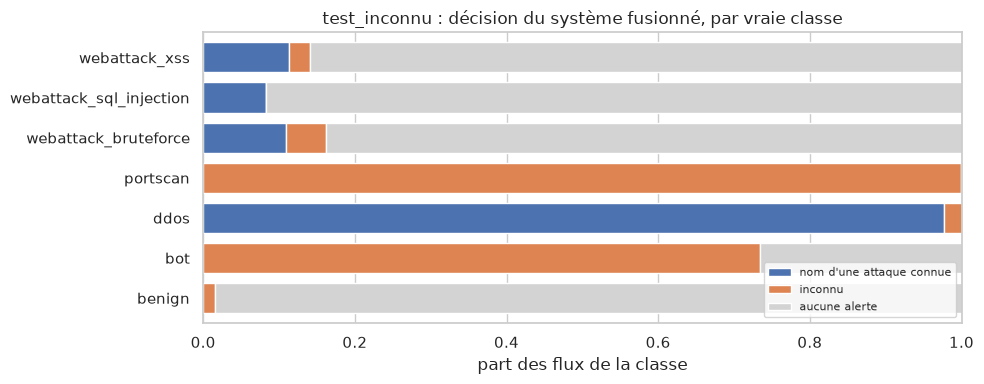

In [6]:
# Figure : ce que deviennent les flux de chaque classe de test_inconnu
to_plot = inconnu_table.copy()
parts = pd.DataFrame({
    "nom d'une attaque connue": to_plot["autre attaque connue"] / to_plot["flux"],
    "inconnu": to_plot["inconnu"] / to_plot["flux"],
    "aucune alerte": to_plot["aucune alerte"] / to_plot["flux"],
})
fig, ax = plt.subplots(figsize=(10, 4))
parts.plot.barh(stacked=True, ax=ax, color=["#4C72B0", "#DD8452", "#D3D3D3"], width=0.75)
ax.set_xlim(0, 1)
ax.set_xlabel("part des flux de la classe")
ax.set_ylabel("")
ax.set_title("test_inconnu : décision du système fusionné, par vraie classe")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(REPORTS / "05_fusion_par_classe.png", dpi=150)
plt.show()

## 4. Sensibilité de l'écart entre alertes, sur val seulement

On ne choisit rien ici : l'écart reste à 5 minutes. On regarde seulement si le nombre d'incidents change beaucoup.

In [7]:
val_alerts = sets["val"][sets["val"]["final"] != BENIGN]
rows = []
for gap in [60, 300, 900]:
    grouped = number_incidents(val_alerts[["src_addr", TS]], gap)
    rows.append({"écart (s)": gap, "alertes": len(grouped), "incidents": grouped["incident"].nunique()})
pd.DataFrame(rows)

,écart (s),alertes,incidents
0,60,28862,552
1,300,28862,197
2,900,28862,80


## 5. Incidents

Chaque incident reçoit son résumé et ses explications :
- **RF** : SHAP sur le flux de l'incident où le RF est le plus sûr, si le RF a signalé au moins un flux ;
- **autoencodeur** : les colonnes les plus mal reconstruites, sur le flux au score d'anomalie le plus haut.

La vraie étiquette va dans un dictionnaire séparé (`verite`), jamais dans l'incident.

In [8]:
explainer = shap.TreeExplainer(rf)
classes = list(rf.classes_)


def build_incidents(set_name):
    """Renvoie (liste des incidents pour les agents, vérité de chaque incident pour l'évaluation)."""
    df = sets[set_name]
    alerts = number_incidents(df[df["final"] != BENIGN])

    incidents = []
    truth = {}
    for number, flows in alerts.groupby("incident"):
        incident_id = "INC-" + set_name + "-" + str(int(number)).zfill(4)
        incident = summarize_incident(incident_id, flows, threshold)

        # Explication de l'autoencodeur : le flux au score le plus haut
        worst_flow = flows.loc[flows["ae_score"].idxmax(), "position"]
        incident["explication_autoencodeur"] = explain_with_autoencoder(autoencoder, Z[set_name][worst_flow],
                                                                        X[set_name][worst_flow], features)

        # Explication du RF : le flux signalé par le RF avec la plus forte probabilité
        supervised = flows[flows["source"] == SOURCE_SUPERVISED]
        if len(supervised) > 0:
            best_row = supervised.loc[supervised["rf_proba"].idxmax()]
            class_index = classes.index(best_row["final"])
            incident["etiquette_expliquee"] = best_row["final"]
            incident["explication_rf"] = explain_with_shap(explainer, X[set_name][best_row["position"]], class_index, features)
        else:
            incident["etiquette_expliquee"] = None
            incident["explication_rf"] = []

        incidents.append(incident)

        # Vérité, gardée à part
        truth[incident_id] = {}
        for label, count in flows[LABEL].value_counts().items():
            truth[incident_id][str(label)] = int(count)
    return incidents, truth


incidents = {}
truths = {}
for set_name in ["test_connu", "test_inconnu"]:
    incidents[set_name], truths[set_name] = build_incidents(set_name)
    print(set_name, ":", len(incidents[set_name]), "incidents")

test_connu : 239 incidents


test_inconnu : 487 incidents


In [9]:
def incident_summary(set_name):
    """Chiffres globaux : combien d'incidents contiennent vraiment une attaque ?"""
    alerts_total = 0
    real = 0
    false = 0
    mixed = 0
    false_flows = 0
    for incident in incidents[set_name]:
        truth = truths[set_name][incident["id"]]
        alerts_total += incident["nb_flux"]
        benign_flows = truth.get(BENIGN, 0)
        if benign_flows == incident["nb_flux"]:
            false += 1
            false_flows += benign_flows
        else:
            real += 1
            if benign_flows > 0:
                mixed += 1
    return {
        "ensemble": set_name,
        "flux en alerte": alerts_total,
        "incidents": len(incidents[set_name]),
        "flux par incident (moyenne)": round(alerts_total / len(incidents[set_name]), 1),
        "incidents avec attaque": real,
        "dont avec aussi du benign": mixed,
        "incidents sans attaque": false,
        "part sans attaque": round(false / len(incidents[set_name]), 3),
        "flux des incidents sans attaque": false_flows,
    }


pd.DataFrame([incident_summary("test_connu"), incident_summary("test_inconnu")]).set_index("ensemble").T

ensemble,test_connu,test_inconnu
flux en alerte,28960.000,262715.000
incidents,239.000,487.000
flux par incident (moyenne),121.200,539.500
incidents avec attaque,7.000,13.000
dont avec aussi du benign,0.000,12.000
incidents sans attaque,232.000,474.000
part sans attaque,0.971,0.973
flux des incidents sans attaque,1482.000,5132.000


In [10]:
def coverage_table(set_name):
    """Pour chaque attaque : combien d'incidents la contiennent, et leur nature."""
    counts = {}
    for incident in incidents[set_name]:
        for label, count in truths[set_name][incident["id"]].items():
            if label == BENIGN:
                continue
            if label not in counts:
                counts[label] = {"incidents": 0, "flux en alerte": 0, "IP sources": set(), "durée max (s)": 0}
            counts[label]["incidents"] += 1
            counts[label]["flux en alerte"] += count
            counts[label]["IP sources"].add(incident["src_addr"])
            counts[label]["durée max (s)"] = max(counts[label]["durée max (s)"], incident["duree_s"])
    table = pd.DataFrame(counts).T
    table["IP sources"] = table["IP sources"].map(len)
    return table.sort_index()


print("test_inconnu")
display(coverage_table("test_inconnu"))
print("test_connu")
display(coverage_table("test_connu"))

test_inconnu


,incidents,flux en alerte,IP sources,durée max (s)
bot,5,540,5,7716.3
ddos,1,95683,1,3736.9
portscan,5,160102,1,707.2
webattack_bruteforce,1,221,1,2500.6
webattack_sql_injection,1,1,1,1476.5
webattack_xss,1,93,1,1476.5


test_connu


,incidents,flux en alerte,IP sources,durée max (s)
dos_goldeneye,1,1015,1,42.7
dos_hulk,1,23849,1,204.8
dos_slowhttptest,1,730,1,114.8
dos_slowloris,1,846,1,225.6
ftp_patator,1,601,1,539.6
heartbleed,1,2,1,120.3
ssh_patator,1,435,1,588.4


In [11]:
# Quelles machines produisent les incidents sans attaque ? Combien de temps durent-ils ?
rows = []
for incident in incidents["test_inconnu"]:
    truth = truths["test_inconnu"][incident["id"]]
    rows.append({
        "src_addr": incident["src_addr"],
        "nb_flux": incident["nb_flux"],
        "duree_s": incident["duree_s"],
        "sans attaque": truth.get(BENIGN, 0) == incident["nb_flux"],
    })
incident_rows = pd.DataFrame(rows)

by_ip = incident_rows.groupby(["src_addr", "sans attaque"]).size().unstack(fill_value=0)
by_ip = by_ip.reindex(columns=[True, False], fill_value=0)
by_ip.columns = ["sans attaque", "avec attaque"]
by_ip = by_ip.sort_values("sans attaque", ascending=False)

print("Durée des incidents sans attaque (s) :")
print(incident_rows.loc[incident_rows["sans attaque"], "duree_s"].describe().round(1).to_string())
print("Machines différentes :", len(by_ip))
by_ip.head(10)

Durée des incidents sans attaque (s) :
count     474.0
mean      381.8
std       608.9
min         0.0
25%         0.0
50%       178.7
75%       491.2
max      5679.4
Machines différentes : 32


,sans attaque,avec attaque
src_addr,,
192.168.10.3,45,0
192.168.10.50,41,0
192.168.10.25,40,0
192.168.10.17,36,0
192.168.10.12,36,0
192.168.10.9,36,1
192.168.10.16,36,0
192.168.10.19,35,0
192.168.10.5,32,1


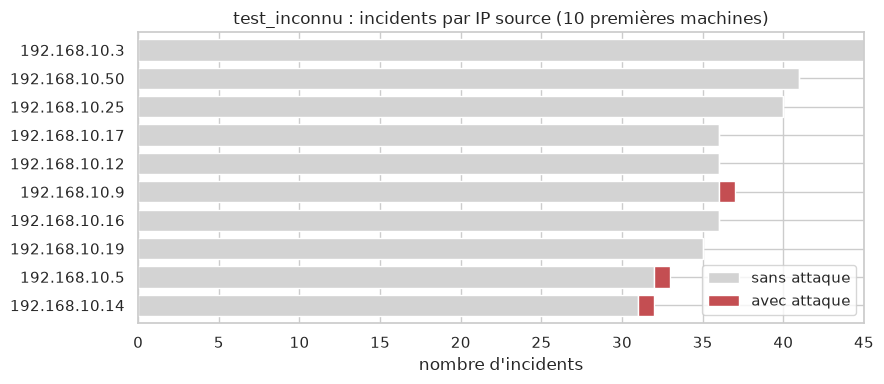

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
top_ips = by_ip.head(10).iloc[::-1]
top_ips.plot.barh(stacked=True, ax=ax, color=["#D3D3D3", "#C44E52"], width=0.75)
ax.set_xlabel("nombre d'incidents")
ax.set_ylabel("")
ax.set_title("test_inconnu : incidents par IP source (10 premières machines)")
fig.tight_layout()
fig.savefig(REPORTS / "05_incidents_par_machine.png", dpi=150)
plt.show()

## 6. Export

- `data/processed/incidents/{test_connu,test_inconnu}.json` : les incidents pour les agents, **sans vraie étiquette** ;
- `data/processed/incidents/verite_{test_connu,test_inconnu}.json` : la vérité, pour l'évaluation seulement ;
- `reports/05_exemple_incident.json` : un exemple versionné dans Git.

In [13]:
NOTE = ("Les étiquettes du RF ne sont qu'un indice pour une attaque inconnue : le RF ne connaît que 7 attaques. "
        "« inconnu » signifie seulement que le flux diffère du trafic normal appris. Aucune action n'est exécutée automatiquement.")

for set_name in incidents:
    # Contrôle : aucun champ de l'incident ne doit donner la vérité
    for incident in incidents[set_name]:
        assert LABEL not in incident and "verite" not in incident

    file_content = {"note": NOTE, "seuil_autoencodeur": round(float(threshold), 4), "ecart_s": GAP_SECONDS,
                    "incidents": incidents[set_name]}
    with open(INCIDENTS_DIR / (set_name + ".json"), "w", encoding="utf-8") as f:
        json.dump(file_content, f, indent=2, ensure_ascii=False)
    with open(INCIDENTS_DIR / ("verite_" + set_name + ".json"), "w", encoding="utf-8") as f:
        json.dump(truths[set_name], f, indent=2, ensure_ascii=False)

    # Relecture : le JSON doit être valide
    with open(INCIDENTS_DIR / (set_name + ".json"), encoding="utf-8") as f:
        back = json.load(f)
    size = (INCIDENTS_DIR / (set_name + ".json")).stat().st_size / 1e6
    print(set_name, ":", len(back["incidents"]), "incidents relus,", round(size, 2), "Mo")

# Exemple : l'incident qui contient le plus de flux
largest = incidents["test_inconnu"][0]
for incident in incidents["test_inconnu"]:
    if incident["nb_flux"] > largest["nb_flux"]:
        largest = incident
with open(REPORTS / "05_exemple_incident.json", "w", encoding="utf-8") as f:
    json.dump(largest, f, indent=2, ensure_ascii=False)
print("Vérité de cet exemple :", truths["test_inconnu"][largest["id"]])
print(json.dumps(largest, indent=2, ensure_ascii=False))

test_connu : 239 incidents relus, 0.38 Mo
test_inconnu : 487 incidents relus, 0.78 Mo
Vérité de cet exemple : {'portscan': 139585, 'benign': 1}
{
  "id": "INC-test_inconnu-0014",
  "src_addr": "172.16.0.1",
  "debut_utc": "2017-07-07 17:51:06",
  "fin_utc": "2017-07-07 17:56:00",
  "debut_local": "2017-07-07 14:51:06",
  "duree_s": 293.7,
  "nb_flux": 139586,
  "etiquettes": {
    "inconnu": 139578,
    "dos_hulk": 8
  },
  "sources": {
    "anomalie": 139578,
    "supervisé": 8
  },
  "nb_machines_dst": 2,
  "nb_ports_dst": 999,
  "machines_dst": {
    "192.168.10.50": 139585,
    "192.168.10.51": 1
  },
  "ports_dst": {
    "80": 144,
    "256": 140,
    "139": 140,
    "1723": 140,
    "23": 140
  },
  "protocoles": {
    "6": 139585,
    "1": 1
  },
  "score_anomalie": {
    "max": 5.1383,
    "moyen": 1.3829,
    "seuil": 0.182
  },
  "proba_rf_max": 0.81,
  "fenetre_max": {
    "w_conn": 44865.0,
    "w_dst_ports": 998.0,
    "w_dst_hosts": 2.0,
    "w_rst_rate": 0.994
  },
  "ex

## Observations

1. **Sur test_connu, le système fusionné signale presque tout.** Part en alerte de 97,97 à 100 % sur toutes les classes. Le bon nom est donné le plus souvent (dos_hulk 23 710 sur 23 849, ftp_patator 601 sur 601). Le point faible reste dos_slowloris : 647 bons noms sur 852, et 199 flux appelés autrement. Fausses alertes : 0,99 %. Rappel : ce test suit l'entraînement dans le temps, le même jour.
2. **Sur test_inconnu, la fusion couvre portscan et DDoS.** 160 102 flux de portscan sur 160 106, 95 683 de DDoS sur 95 683. Bot : 540 sur 735 (73,5 %), chiffre fragile (49 % en moyenne sur 5 graines, notebook 04c). Attaques web : bruteforce 16,3 %, XSS 14,1 %, sql_injection 1 sur 12. Fausses alertes : 1,53 %.
3. **La fusion apporte peu par rapport à l'autoencodeur seul, sauf sur les attaques web et pour le nom.** Elle ne réussit pas mieux sur portscan et DDoS, déjà à environ 100 %. Elle améliore les attaques web (bruteforce 5,4 % → 16,3 %, XSS 2,7 % → 14,1 %). Le RF donne en plus un nom, mais souvent faux : 97,7 % des flux de DDoS sont appelés dos_hulk.
4. **Les incidents réduisent énormément le volume.** 262 715 flux en alerte deviennent **487 incidents** sur test_inconnu (540 flux par incident en moyenne), et 28 960 deviennent 239 incidents sur test_connu.
5. **Mais 97,3 % des incidents de test_inconnu ne contiennent aucune attaque** (474 sur 487), et 97,1 % sur test_connu (232 sur 239). C'est le résultat le plus important de ce notebook. La précision de 97,7 % mesurée par flux ne vaut donc rien au niveau de l'analyste : elle vient du très grand nombre de flux dans quelques gros incidents. **Le système ne réduit pas encore assez la charge de travail.**
6. **Les incidents sans attaque sont petits et répartis.** Ils regroupent 5 132 flux en tout (environ 11 par incident), durent 179 s en médiane et viennent de 32 machines, aucune ne dominant vraiment (45 au plus). Il n'y a donc pas une seule machine bruyante à écarter. Leur petite taille suggère une priorisation par nombre de flux ou par score, à régler **sur val**, jamais sur les tests.
7. **Au niveau des incidents, toutes les attaques de test_inconnu apparaissent.** Chaque classe est présente dans au moins un incident : portscan 5, bot 5 (une par machine source), DDoS 1, bruteforce 1, et XSS et sql_injection réunies dans 1 incident. Même si seuls 14 à 16 % des flux web sont signalés, l'analyste a donc un incident à examiner pour chacune. C'est une nuance importante par rapport aux chiffres par flux, mais ces incidents sont noyés parmi les 474 sans attaque.
8. **Il y a des incidents mixtes.** 12 des 13 incidents avec attaque de test_inconnu contiennent aussi des flux benign (943 flux en tout). Les incidents de bot sont longs (jusqu'à 7 716 s), car ces machines ont aussi une activité normale.
9. **Le nombre d'incidents dépend fortement de l'écart choisi.** Sur val : 552 incidents à 1 minute, 197 à 5 minutes, 80 à 15 minutes. L'écart de 5 minutes reste un choix fixé à l'avance, sans justification forte. Le même compte n'est pas stable : il faudra le dire dans le rapport.
10. **Les explications ont une limite.** Elles portent sur un seul flux par incident. Dans l'exemple enregistré (139 586 flux, presque tous du portscan), `etiquette_expliquee` vaut « dos_hulk » alors que seuls 8 flux portent cette étiquette, contre 139 578 « inconnu ». Les agents devront lire `etiquettes` et `sources`, sans s'arrêter à ce champ.
11. **La vraie étiquette est bien séparée.** Elle est dans les fichiers `verite_*.json`, et un contrôle du code vérifie qu'elle n'est dans aucun incident.